<a href="https://colab.research.google.com/github/mariyamfathima01/sales-data-analysis/blob/main/Sales_Data_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📊 Retail Sales Data Analysis Using Python

## Project Introduction

This project focuses on analysing retail sales data using Python.
The main goal is to understand sales performance, product profitability,
regional trends, and the relationship between discounts and profit.

Through data cleaning, exploratory data analysis, and visualisation,
this project identifies important business insights that can support
better decision-making.

## Objectives
- Analyse overall sales and profit.
- Identify top-performing product categories.
- Compare sales across different regions.
- Identify profitable and loss-making products.
- Understand the relationship between discounts and profit.

## Technologies Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Google Colab

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
import pandas as pd

df = pd.read_csv('/content/SampleSuperstore.csv')

print("Dataset loaded successfully!")

df.head()

Dataset loaded successfully!


,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit
0,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,261.9600,2,0.00,41.9136
1,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,731.9400,3,0.00,219.5820
2,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,14.6200,2,0.00,6.8714
3,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,957.5775,5,0.45,-383.0310
4,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,22.3680,2,0.20,2.5164


In [3]:
print("Number of rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Number of rows and columns: (9994, 13)

Column names:
['Ship Mode', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Category', 'Sub-Category', 'Sales', 'Quantity', 'Discount', 'Profit']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Ship Mode     9994 non-null   object 
 1   Segment       9994 non-null   object 
 2   Country       9994 non-null   object 
 3   City          9994 non-null   object 
 4   State         9994 non-null   object 
 5   Postal Code   9994 non-null   int64  
 6   Region        9994 non-null   object 
 7   Category      9994 non-null   object 
 8   Sub-Category  9994 non-null   object 
 9   Sales         9994 non-null   float64
 10  Quantity      9994 non-null   int64  
 11  Discount      9994 non-null   float64
 12  Profit        9994 non-null   float64
dtypes: float64(3), int

In [4]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

# Statistical summary
print("\nStatistical Summary:")
df.describe()

Missing Values:
Ship Mode       0
Segment         0
Country         0
City            0
State           0
Postal Code     0
Region          0
Category        0
Sub-Category    0
Sales           0
Quantity        0
Discount        0
Profit          0
dtype: int64

Duplicate Records:
17

Statistical Summary:


,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,55190.379428,229.858001,3.789574,0.156203,28.656896
std,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,90008.000000,209.940000,5.000000,0.200000,29.364000
max,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [5]:
# Remove duplicate records
df_clean = df.drop_duplicates()

# Check the cleaned dataset
print("Original dataset:", df.shape)

print("Cleaned dataset:", df_clean.shape)

print("Duplicates remaining:", df_clean.duplicated().sum())

Original dataset: (9994, 13)
Cleaned dataset: (9977, 13)
Duplicates remaining: 0


In [6]:
# Total sales by product category

category_sales = df_clean.groupby('Category')['Sales'].sum()

print("Total Sales by Category:")
print(category_sales.sort_values(ascending=False))

Total Sales by Category:
Category
Technology         836154.0330
Furniture          741306.3133
Office Supplies    718735.2440
Name: Sales, dtype: float64


In [7]:
# Total profit by product category

category_profit = df_clean.groupby('Category')['Profit'].sum()

print("Total Profit by Category:")
print(category_profit.sort_values(ascending=False))

Total Profit by Category:
Category
Technology         145454.9481
Office Supplies    122364.6608
Furniture           18421.8137
Name: Profit, dtype: float64


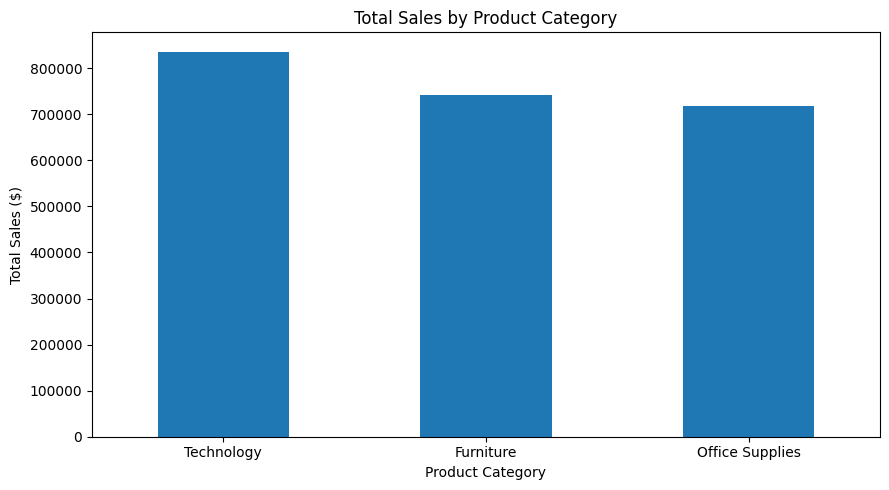

In [8]:
plt.figure(figsize=(9, 5))

category_sales.sort_values(ascending=False).plot(
    kind='bar',
    title='Total Sales by Product Category'
)

plt.xlabel('Product Category')
plt.ylabel('Total Sales ($)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [9]:
# Calculate total sales by region

region_sales = df_clean.groupby('Region')['Sales'].sum()

print("Total Sales by Region:")
print(region_sales.sort_values(ascending=False))

Total Sales by Region:
Region
West       725255.6365
East       678435.1960
Central    500782.8528
South      391721.9050
Name: Sales, dtype: float64


In [10]:
# Calculate total profit by region

region_profit = df_clean.groupby('Region')['Profit'].sum()

print("Total Profit by Region:")
print(region_profit.sort_values(ascending=False))

Total Profit by Region:
Region
West       108329.8079
East        91506.3092
South       46749.4303
Central     39655.8752
Name: Profit, dtype: float64


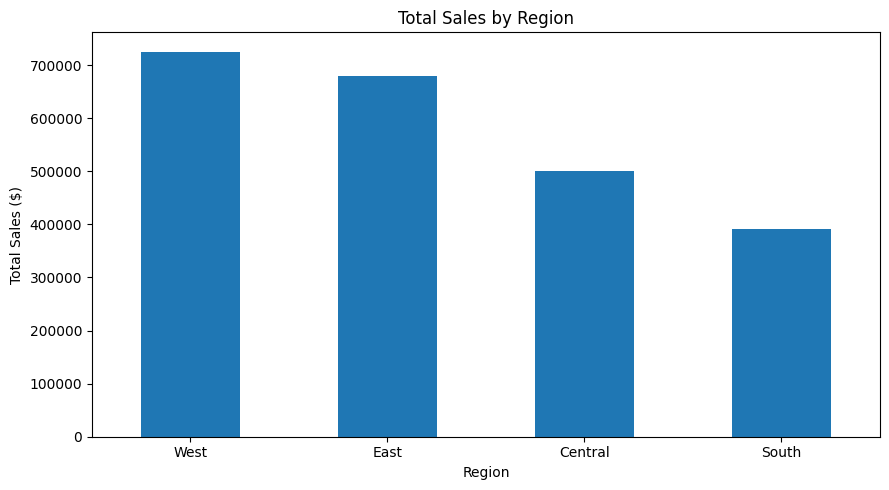

In [11]:
plt.figure(figsize=(9, 5))

region_sales.sort_values(ascending=False).plot(
    kind='bar',
    title='Total Sales by Region'
)

plt.xlabel('Region')
plt.ylabel('Total Sales ($)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [12]:
subcategory_sales = df_clean.groupby('Sub-Category')['Sales'].sum()

print("Total Sales by Sub-Category:")
print(subcategory_sales.sort_values(ascending=False))

Total Sales by Sub-Category:
Sub-Category
Phones         330007.0540
Chairs         327777.7610
Storage        223843.6080
Tables         206965.5320
Binders        203409.1690
Machines       189238.6310
Accessories    167380.3180
Copiers        149528.0300
Bookcases      114879.9963
Appliances     107532.1610
Furnishings     91683.0240
Paper           78224.1420
Supplies        46673.5380
Art             27107.0320
Envelopes       16476.4020
Labels          12444.9120
Fasteners        3024.2800
Name: Sales, dtype: float64


In [13]:
subcategory_profit = df_clean.groupby('Sub-Category')['Profit'].sum()

print("Total Profit by Sub-Category:")
print(subcategory_profit.sort_values(ascending=False))

Total Profit by Sub-Category:
Sub-Category
Copiers        55617.8249
Phones         44515.7306
Accessories    41936.6357
Paper          33944.2395
Binders        30228.0003
Chairs         26567.1278
Storage        21278.8264
Appliances     18138.0054
Furnishings    13052.7230
Envelopes       6964.1767
Art             6524.6118
Labels          5526.3820
Machines        3384.7569
Fasteners        949.5182
Supplies       -1189.0995
Bookcases      -3472.5560
Tables        -17725.4811
Name: Profit, dtype: float64


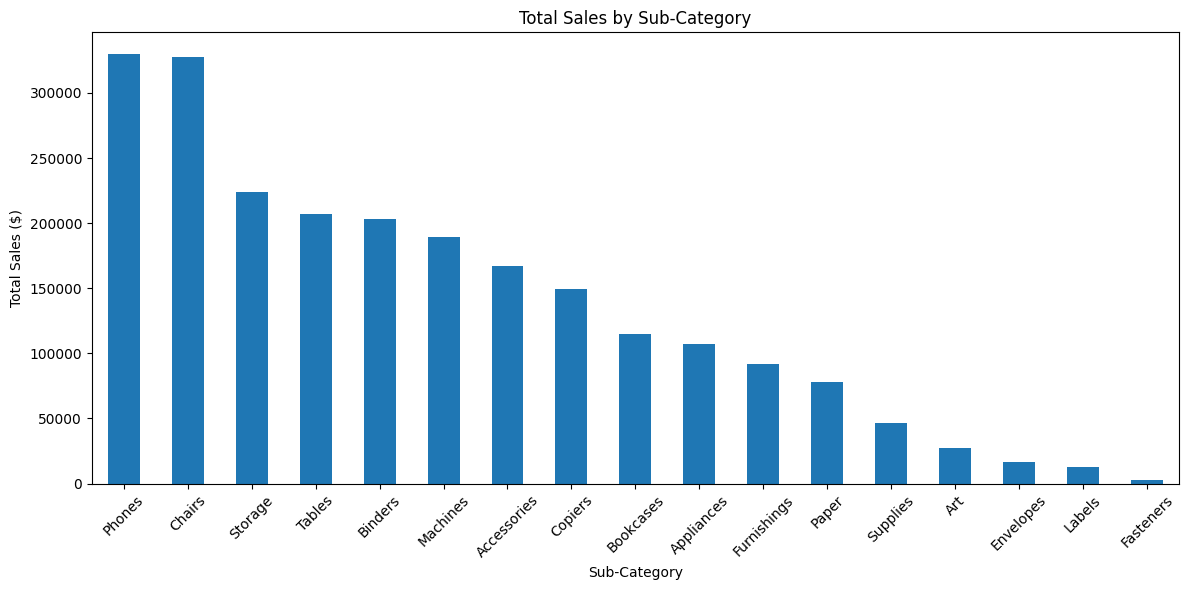

In [14]:
plt.figure(figsize=(12, 6))

subcategory_sales.sort_values(ascending=False).plot(
    kind='bar',
    title='Total Sales by Sub-Category'
)

plt.xlabel('Sub-Category')
plt.ylabel('Total Sales ($)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

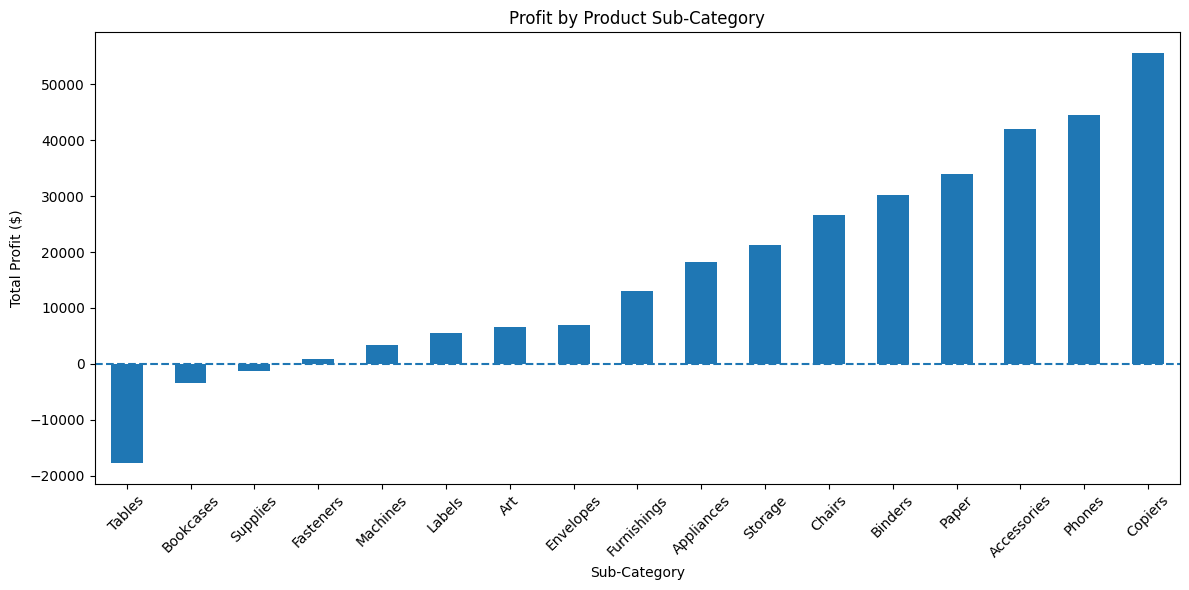

In [15]:
plt.figure(figsize=(12, 6))

subcategory_profit.sort_values().plot(
    kind='bar',
    title='Profit by Product Sub-Category'
)

plt.xlabel('Sub-Category')
plt.ylabel('Total Profit ($)')
plt.axhline(y=0, linestyle='--')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [16]:
discount_profit = df_clean.groupby('Discount')['Profit'].mean()

print("Average Profit by Discount:")
print(discount_profit.sort_values())

Average Profit by Discount:
Discount
0.50   -310.703456
0.45   -226.646464
0.40   -111.927429
0.80   -102.116395
0.70    -95.874060
0.32    -88.560656
0.30    -45.828401
0.60    -43.077212
0.20     24.721217
0.15     27.288298
0.00     67.024108
0.10     96.055074
Name: Profit, dtype: float64


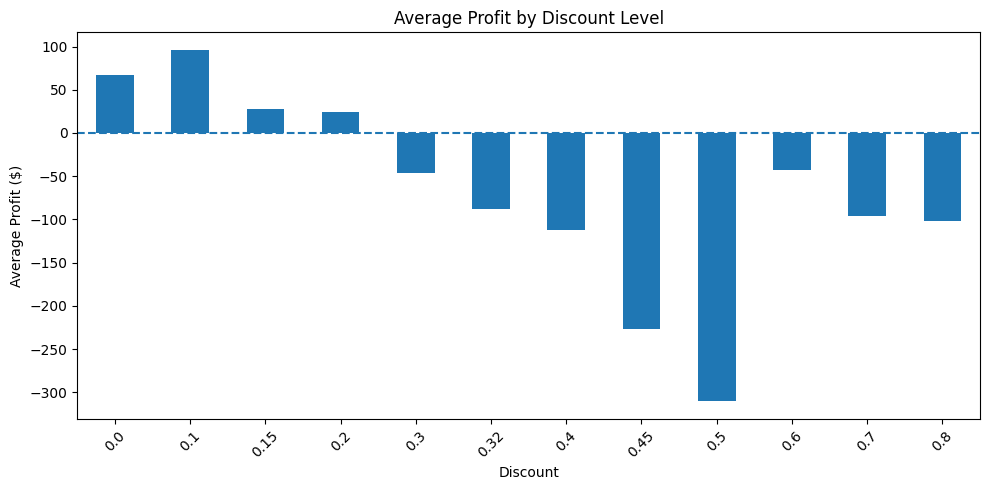

In [17]:
plt.figure(figsize=(10, 5))

discount_profit.sort_index().plot(
    kind='bar',
    title='Average Profit by Discount Level'
)

plt.xlabel('Discount')
plt.ylabel('Average Profit ($)')
plt.axhline(y=0, linestyle='--')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [18]:
print("SALES DATA ANALYSIS - KEY FINDINGS")
print("=" * 40)

print("\n1. Best Sales Category:")
print(category_sales.idxmax())

print("\n2. Most Profitable Category:")
print(category_profit.idxmax())

print("\n3. Highest Sales Sub-Category:")
print(subcategory_sales.idxmax())

print("\n4. Most Profitable Sub-Category:")
print(subcategory_profit.idxmax())

print("\n5. Biggest Loss-Making Sub-Category:")
print(subcategory_profit.idxmin())

print("\n6. Discount Level with Highest Average Profit:")
print(discount_profit.idxmax())

print("\n7. Discount Level with Lowest Average Profit:")
print(discount_profit.idxmin())

print("\n8. Number of Rows After Removing Duplicates:")
print(len(df_clean))

print("\nAnalysis completed successfully!")

SALES DATA ANALYSIS - KEY FINDINGS

1. Best Sales Category:
Technology

2. Most Profitable Category:
Technology

3. Highest Sales Sub-Category:
Phones

4. Most Profitable Sub-Category:
Copiers

5. Biggest Loss-Making Sub-Category:
Tables

6. Discount Level with Highest Average Profit:
0.1

7. Discount Level with Lowest Average Profit:
0.5

8. Number of Rows After Removing Duplicates:
9977

Analysis completed successfully!
